# Mardi — Travailler avec des données réelles

L'objectif est de voir ce qui se passe souvent avec des données réelles avant toute analyse.

## Objectifs

À la fin de la séance, vous saurez :

- lire un fichier CSV ;
- inspecter rapidement un jeu de données ;
- repérer des valeurs manquantes ;
- repérer des doublons ;
- détecter quelques valeurs impossibles ou suspectes ;
- tracer les positions latitude/longitude à un instant donné ;
- comprendre quelques erreurs simples ;
- effectuer quelques corrections de base.

Nous utiliserons le fichier **`Orage_NosyBe.csv`**.

## 1. Charger pandas

In [25]:
import pandas as pd

## 2. Lire le fichier

Le fichier `train_messy.csv` doit être dans le même dossier que ce notebook.

In [26]:
data = pd.read_csv("../data/Orage_NosyBe.csv")
data.head()

,year,month,day,hour,minute,lat,lon,intensity,size,distance,Storm_NosyBe_1h,Storm_NosyBe_3h
0,2004,1,19,10,30,-13.6126,48.2281,468.0,1422.0,10.44,0,1
1,2004,1,19,10,45,-13.7039,48.2598,488.0,1881.0,13.34,0,1
2,2004,1,19,11,0,-13.7953,48.2918,424.0,1746.0,16.28,0,1
3,2004,1,19,11,15,-14.2190,48.3387,485.0,4167.0,30.41,0,1
4,2004,1,19,11,30,-13.2851,49.2745,155.0,207.0,19.10,0,1


## 3. Première inspection

Avant de commencer une analyse, il faut d'abord comprendre ce que contient le fichier.

### Exercice 1 — Combien de lignes et de colonnes contient le fichier ?

In [27]:
data.shape

(51082, 12)

### Exercice 2 — Affichez les noms des colonnes.

In [28]:
data.columns

Index(['year', 'month', 'day', 'hour', 'minute', 'lat', 'lon', 'intensity',
       'size', 'distance', 'Storm_NosyBe_1h', 'Storm_NosyBe_3h'],
      dtype='object')

### Exercice 3 — Affichez les types des colonnes.

In [29]:
data.dtypes

year                 int64
month                int64
day                  int64
hour                 int64
minute               int64
lat                float64
lon                float64
intensity          float64
size               float64
distance           float64
Storm_NosyBe_1h      int64
Storm_NosyBe_3h      int64
dtype: object

Certaines colonnes numériques peuvent apparaître comme `object` à cause de valeurs enregistrées sous forme de texte.

## 4. Valeurs manquantes

### Exercice 4 — Comptez les valeurs manquantes dans chaque colonne.

In [30]:
data.isna().sum()

year               0
month              0
day                0
hour               0
minute             0
lat                5
lon                5
intensity          8
size               8
distance           8
Storm_NosyBe_1h    0
Storm_NosyBe_3h    0
dtype: int64

## 5. Doublons

### Exercice 5 — Comptez les lignes dupliquées.

In [31]:
data.duplicated().sum()

5

### Exercice 6 — Affichez les lignes dupliquées.

In [32]:
data[data.duplicated()]

,year,month,day,hour,minute,lat,lon,intensity,size,distance,Storm_NosyBe_1h,Storm_NosyBe_3h
51077,2010,12,17,21,0,-13.7545,47.9663,228.0,1836.0,17.49,0,0
51078,2018,3,3,19,0,-12.9845,49.2768,411.0,36324.0,24.19,0,0
51079,2013,3,4,17,30,-13.3070,49.0156,110.0,135.0,14.04,0,0
51080,2011,2,3,18,45,-13.6404,49.9996,221.0,7056.0,31.32,0,0
51081,2005,1,14,21,45,-12.8418,47.5621,164.0,5472.0,18.60,0,0


## 6. Vérifier des valeurs impossibles ou suspectes

### Exercice 7 — Vérifiez `month`.

In [33]:
print(data["month"].min())
print(data["month"].max())

1
13


Une valeur de 13 est invalide.

### Exercice 8 — Vérifiez `hour`.

In [34]:
print(data["hour"].min())
print(data["hour"].max())

0
27


Une valeur de 27 est invalide.

### Exercice 9 — Vérifiez `lat`.

In [35]:
print(data["lat"].min())
print(data["lat"].max())

-14.9995
95.0


Une latitude de 95 est impossible.

### Exercice 10 — Vérifiez `lon`.

In [36]:
print(data["lon"].min())
print(data["lon"].max())

47.5003
190.0


Une longitude de 190 est impossible.

### Exercice 11 — Trouvez les lignes où le mois est invalide.

In [37]:
data[data["month"] > 12]

,year,month,day,hour,minute,lat,lon,intensity,size,distance,Storm_NosyBe_1h,Storm_NosyBe_3h
49417,2019,13,14,16,15,-12.772,49.2046,211.0,927.0,28.32,0,0


### Exercice 12 — Trouvez les lignes où l'heure est invalide.

In [38]:
data[data["hour"] > 23]

,year,month,day,hour,minute,lat,lon,intensity,size,distance,Storm_NosyBe_1h,Storm_NosyBe_3h
20985,2010,12,2,27,30,-14.2948,48.7879,136.0,702.0,32.14,0,0


## 7. Tracer les positions avec Cartopy

Nous allons maintenant représenter les positions des orages sur une carte.

Pour cela, nous utilisons :

- `matplotlib` pour tracer ;
- `cartopy` pour afficher une vraie carte avec les côtes et les frontières.

Ici, nous allons choisir **un instant donné** et afficher les points de latitude/longitude correspondants.

### Charger les outils pour la carte

In [39]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

### Observer quelques dates/heures disponibles

Avant de filtrer les données, regardons quelques combinaisons de date et d'heure présentes dans le fichier.

In [40]:
data[["year", "month", "day", "hour", "minute"]].drop_duplicates().head(10)

,year,month,day,hour,minute
0,2004,1,19,10,30
1,2004,1,19,10,45
2,2004,1,19,11,0
3,2004,1,19,11,15
4,2004,1,19,11,30
5,2004,1,19,11,45
6,2004,1,19,12,0
7,2004,1,19,12,15
8,2004,1,19,12,30
9,2004,1,19,12,45


### Exercice 13 — Sélectionner un instant

In [41]:
selection = data[
    (data["year"] == 2004)
    & (data["month"] == 1)
    & (data["day"] == 19)
    & (data["hour"] == 10)
    & (data["minute"] == 30)
]

selection.head()

,year,month,day,hour,minute,lat,lon,intensity,size,distance,Storm_NosyBe_1h,Storm_NosyBe_3h
0,2004,1,19,10,30,-13.6126,48.2281,468.0,1422.0,10.44,0,1


### Exercice 14 — Garder seulement les latitudes et longitudes valides

In [42]:
selection_map = selection.dropna(subset=["lat", "lon"]).copy()

selection_map = selection_map[
    (selection_map["lat"] >= -90)
    & (selection_map["lat"] <= 90)
    & (selection_map["lon"] >= -180)
    & (selection_map["lon"] <= 180)
]

selection_map.head()

,year,month,day,hour,minute,lat,lon,intensity,size,distance,Storm_NosyBe_1h,Storm_NosyBe_3h
0,2004,1,19,10,30,-13.6126,48.2281,468.0,1422.0,10.44,0,1


### Exercice 15 — Tracer les points sur une carte

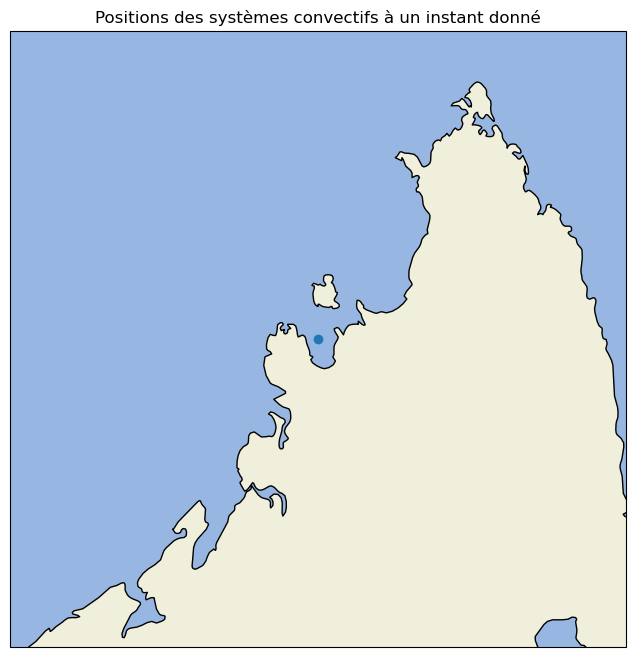

In [43]:
fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)

ax.scatter(
    selection_map["lon"],
    selection_map["lat"],
    transform=ccrs.PlateCarree()
)

if len(selection_map) > 0:
    lon_min = selection_map["lon"].min() - 2
    lon_max = selection_map["lon"].max() + 2
    lat_min = selection_map["lat"].min() - 2
    lat_max = selection_map["lat"].max() + 2
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

ax.set_title("Positions des systèmes convectifs à un instant donné")
plt.show()

La carte montre les positions des systèmes convectifs observés à cet instant.

## 8. Nettoyer une colonne numérique

### Exercice 16 — Convertissez `intensity` en nombre

In [44]:
data["intensity"] = pd.to_numeric(data["intensity"], errors="coerce")
data["intensity"].dtype

dtype('float64')

### Exercice 17 — Faites la même chose pour `size` et `distance`.

In [45]:
data["size"] = pd.to_numeric(data["size"], errors="coerce")
data["distance"] = pd.to_numeric(data["distance"], errors="coerce")

## 9. Supprimer les doublons

### Exercice 18 — Créez `data_clean` sans doublons.

In [46]:
data_clean = data.drop_duplicates()
data_clean.shape

(51077, 12)

## 10. Comprendre une erreur fréquente

### Exercice 19 — Corrigez le nom de colonne.

In [47]:
data["intensity"].head()

0    468.0
1    488.0
2    424.0
3    485.0
4    155.0
Name: intensity, dtype: float64

## 11. Bilan

Nous avons identifié et corrigé plusieurs problèmes simples rencontrés dans des fichiers réels.

L'objectif n'est pas encore de faire une analyse complète, mais de vérifier que les données sont exploitables avant de commencer.